# Мета роботи

Ознайомитися з базовими методами навчання без учителя та обробки текстових даних: зниженням розмірності, візуалізацією і кластеризацією даних, а також побудовою базового workflow класифікації текстів з використанням бібліотеки **Scikit-learn**.

---

# Завдання

## 1. Зниження розмірності та візуалізація даних

- Взяти датасет, з яким ви працювали в лабораторній роботі №1.
- Застосувати `sklearn.decomposition.PCA` для зниження розмірності даних.
- На отриманих даних навчити один з алгоритмів класифікації з Lab 1 та порівняти результати класифікації "до" та "після" PCA.
- Зробити висновки: як PCA вплинув на якість класифікації; наскільки вдалося зменшити кількість ознак; чи змінився час навчання моделі.
- Для того самого датасету застосувати `sklearn.manifold.TSNE` для зниження розмірності до 2D.
- Візуалізувати отримані дані, використовуючи кольори для позначення класів, та пояснити результат.

## 2. Кластерний аналіз

- Взяти датасет з лабораторної роботи №1. **Не використовувати мітки класів (target) під час кластеризації.**
- Виконати кластеризацію даних за допомогою алгоритму K-Means.
- Визначити доцільну кількість кластерів за допомогою Elbow Method та/або Silhouette Score.
- Візуалізувати отримані кластери у 2D за допомогою PCA або t-SNE.
- Після виконання кластеризації порівняти отримані кластери зі справжніми класами датасету.
- Зробити висновок: чи відповідає знайдена кластерна структура реальним класам?
- Якщо датасет містить велику кількість класів, для спрощення аналізу можна залишити 2–3 класи, обґрунтувавши свій вибір.
- **Важливо:** кластер і клас — не одне й те саме. Не очікується, що K-Means обов'язково відтворить початкові класи датасету. Потрібно проаналізувати та пояснити отриманий результат.

## 3. Обробка та класифікація текстових даних

- Завантажити набір текстових даних з мітками класів.
- Провести передобробку текстів (наприклад, видалення стоп-слів та пунктуації).
- За допомогою `WordCloud` візуалізувати найбільш характерні слова/словосполучення для кожного класу та пояснити отримані результати.
- Векторизувати тексти, наприклад за допомогою `sklearn.feature_extraction.text.TfidfVectorizer`.
- Навчити модель класифікації текстів та оцінити якість класифікації за відповідними метриками.

In [421]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.manifold import TSNE
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
import time
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_samples, silhouette_score
import nltk
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('tagsets_json')
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
import re
import string
from wordcloud import WordCloud
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.naive_bayes import MultinomialNB

[nltk_data] Downloading package punkt_tab to /Users/yurab/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /Users/yurab/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /Users/yurab/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /Users/yurab/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package tagsets_json to
[nltk_data]     /Users/yurab/nltk_data...
[nltk_data]   Package tagsets_json is already up-to-date!


### 1. Завантаження та повторення необхідної обробки даних, встановлених у лаб. 1

In [65]:
data = pd.read_csv('/Users/yurab/Desktop/Python for university/Intelligent-analysis/Lab 1 (Basic classification algorithms)/gta6_fan_expectations_2026.csv')
data

,respondent_id,age,gender,region,primary_platform,favorite_previous_gta,years_following_gta6,primary_info_source,trailer1_times_watched,most_anticipated_feature,hype_score_1to10,confidence_rockstar_delivers_1to5,preorder_intent,willingness_to_pay_usd,expected_firstweek_hours,expects_release_delay,worried_about_price,follows_rockstar_socials,hype_change_vs_6mo_ago,overall_sentiment
0,R100000,30,Male,Europe,Undecided,GTA San Andreas,5,Reddit,13,Better driving physics,10,5,No,96.0,19,Yes,No,Yes,Same,Very Positive
1,R100001,29,Male,Europe,PC,GTA San Andreas,4,X/Twitter,15,Dual protagonists (Jason & Lucia),10,3,Yes,70.0,10,No,No,No,Same,Very Positive
2,R100002,28,Female,Europe,Xbox Series X/S,GTA V,6,YouTube,9,Story & narrative depth,7,5,Maybe,81.0,6,No,No,Yes,Increased,Positive
3,R100003,30,Male,Europe,Xbox Series X/S,GTA Vice City,8,Gaming news sites,6,Online/multiplayer mode,8,4,Yes,80.0,11,Yes,No,Yes,Increased,Very Positive
4,R100004,40,Male,Europe,PlayStation 5,GTA V,10,TikTok,8,Realistic economy & businesses,8,4,No,69.0,25,Yes,Yes,No,Same,Very Positive
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5995,R105995,15,Male,Asia-Pacific,PlayStation 5,GTA San Andreas,9,Official Rockstar trailer,8,Open-world Vice City map,10,3,Yes,94.0,12,Yes,No,Yes,Same,Very Positive
5996,R105996,22,Male,North America,PC,GTA V,2,Gaming news sites,11,Open-world Vice City map,10,4,Yes,108.0,25,Yes,No,Yes,Increased,Very Positive
5997,R105997,36,Male,North America,PlayStation 5,GTA IV,1,TikTok,4,Deeper character customization,8,3,Yes,68.0,17,Yes,No,Yes,Increased,Very Positive
5998,R105998,13,Non-binary,Europe,PlayStation 5,GTA Vice City,1,X/Twitter,5,Open-world Vice City map,7,2,Yes,43.0,12,Yes,No,Yes,Same,Positive


Видалення *respondent_id*

In [66]:
data = data.drop(['respondent_id'], axis=1)
data

,age,gender,region,primary_platform,favorite_previous_gta,years_following_gta6,primary_info_source,trailer1_times_watched,most_anticipated_feature,hype_score_1to10,confidence_rockstar_delivers_1to5,preorder_intent,willingness_to_pay_usd,expected_firstweek_hours,expects_release_delay,worried_about_price,follows_rockstar_socials,hype_change_vs_6mo_ago,overall_sentiment
0,30,Male,Europe,Undecided,GTA San Andreas,5,Reddit,13,Better driving physics,10,5,No,96.0,19,Yes,No,Yes,Same,Very Positive
1,29,Male,Europe,PC,GTA San Andreas,4,X/Twitter,15,Dual protagonists (Jason & Lucia),10,3,Yes,70.0,10,No,No,No,Same,Very Positive
2,28,Female,Europe,Xbox Series X/S,GTA V,6,YouTube,9,Story & narrative depth,7,5,Maybe,81.0,6,No,No,Yes,Increased,Positive
3,30,Male,Europe,Xbox Series X/S,GTA Vice City,8,Gaming news sites,6,Online/multiplayer mode,8,4,Yes,80.0,11,Yes,No,Yes,Increased,Very Positive
4,40,Male,Europe,PlayStation 5,GTA V,10,TikTok,8,Realistic economy & businesses,8,4,No,69.0,25,Yes,Yes,No,Same,Very Positive
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5995,15,Male,Asia-Pacific,PlayStation 5,GTA San Andreas,9,Official Rockstar trailer,8,Open-world Vice City map,10,3,Yes,94.0,12,Yes,No,Yes,Same,Very Positive
5996,22,Male,North America,PC,GTA V,2,Gaming news sites,11,Open-world Vice City map,10,4,Yes,108.0,25,Yes,No,Yes,Increased,Very Positive
5997,36,Male,North America,PlayStation 5,GTA IV,1,TikTok,4,Deeper character customization,8,3,Yes,68.0,17,Yes,No,Yes,Increased,Very Positive
5998,13,Non-binary,Europe,PlayStation 5,GTA Vice City,1,X/Twitter,5,Open-world Vice City map,7,2,Yes,43.0,12,Yes,No,Yes,Same,Positive


Виконання всіх необхідних трансформацій як label_encoding one_hot_encoding, встановлених лаб. 1

In [67]:
data['gender'] = data['gender'].where(data['gender'].isin(['Male', 'Female']), 'Non-binary')
mean = data['willingness_to_pay_usd'].mean()
data['willingness_to_pay_usd'] = data['willingness_to_pay_usd'].fillna(int(mean))
data = pd.get_dummies(data, columns=['gender', 'region', 'primary_platform', 'favorite_previous_gta', 'primary_info_source', 'most_anticipated_feature'], dtype=int)
preorder = {'No': 0, 'Maybe': 1, 'Yes': 2}
hype_change = {'Decreased': 0, 'Same': 1, 'Increased': 2}
sentiment = {'Neutral/Cautious': 0, 'Positive': 1, 'Very Positive': 2}
data['preorder_intent'] = data['preorder_intent'].map(preorder)
data['hype_change_vs_6mo_ago'] = data['hype_change_vs_6mo_ago'].map(hype_change)
data['overall_sentiment'] = data['overall_sentiment'].map(sentiment)
array = ['expects_release_delay', 'worried_about_price', 'follows_rockstar_socials']
for i in array:
    for j in range(len(data[i])):
        if data.loc[j, i] == 'Yes':
            data.loc[j, i] = 1
        else:
            data.loc[j, i] = 0
data

,age,years_following_gta6,trailer1_times_watched,hype_score_1to10,confidence_rockstar_delivers_1to5,preorder_intent,willingness_to_pay_usd,expected_firstweek_hours,expects_release_delay,worried_about_price,...,most_anticipated_feature_Better driving physics,most_anticipated_feature_Deeper character customization,most_anticipated_feature_Dual protagonists (Jason & Lucia),most_anticipated_feature_Graphics & ray tracing,most_anticipated_feature_Improved police/AI systems,most_anticipated_feature_Map size & exploration,most_anticipated_feature_Online/multiplayer mode,most_anticipated_feature_Open-world Vice City map,most_anticipated_feature_Realistic economy & businesses,most_anticipated_feature_Story & narrative depth
0,30,5,13,10,5,0,96.0,19,1,0,...,1,0,0,0,0,0,0,0,0,0
1,29,4,15,10,3,2,70.0,10,0,0,...,0,0,1,0,0,0,0,0,0,0
2,28,6,9,7,5,1,81.0,6,0,0,...,0,0,0,0,0,0,0,0,0,1
3,30,8,6,8,4,2,80.0,11,1,0,...,0,0,0,0,0,0,1,0,0,0
4,40,10,8,8,4,0,69.0,25,1,1,...,0,0,0,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5995,15,9,8,10,3,2,94.0,12,1,0,...,0,0,0,0,0,0,0,1,0,0
5996,22,2,11,10,4,2,108.0,25,1,0,...,0,0,0,0,0,0,0,1,0,0
5997,36,1,4,8,3,2,68.0,17,1,0,...,0,1,0,0,0,0,0,0,0,0
5998,13,1,5,7,2,2,43.0,12,1,0,...,0,0,0,0,0,0,0,1,0,0


#### Підготовка даних до навчання

Обираємо змінні `Х` по яким будемо передбачувати. Фактично прибираємо лише колонку `preorder_intent`

In [68]:
X = data.drop('preorder_intent', axis=1)
X

,age,years_following_gta6,trailer1_times_watched,hype_score_1to10,confidence_rockstar_delivers_1to5,willingness_to_pay_usd,expected_firstweek_hours,expects_release_delay,worried_about_price,follows_rockstar_socials,...,most_anticipated_feature_Better driving physics,most_anticipated_feature_Deeper character customization,most_anticipated_feature_Dual protagonists (Jason & Lucia),most_anticipated_feature_Graphics & ray tracing,most_anticipated_feature_Improved police/AI systems,most_anticipated_feature_Map size & exploration,most_anticipated_feature_Online/multiplayer mode,most_anticipated_feature_Open-world Vice City map,most_anticipated_feature_Realistic economy & businesses,most_anticipated_feature_Story & narrative depth
0,30,5,13,10,5,96.0,19,1,0,1,...,1,0,0,0,0,0,0,0,0,0
1,29,4,15,10,3,70.0,10,0,0,0,...,0,0,1,0,0,0,0,0,0,0
2,28,6,9,7,5,81.0,6,0,0,1,...,0,0,0,0,0,0,0,0,0,1
3,30,8,6,8,4,80.0,11,1,0,1,...,0,0,0,0,0,0,1,0,0,0
4,40,10,8,8,4,69.0,25,1,1,0,...,0,0,0,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5995,15,9,8,10,3,94.0,12,1,0,1,...,0,0,0,0,0,0,0,1,0,0
5996,22,2,11,10,4,108.0,25,1,0,1,...,0,0,0,0,0,0,0,1,0,0
5997,36,1,4,8,3,68.0,17,1,0,1,...,0,1,0,0,0,0,0,0,0,0
5998,13,1,5,7,2,43.0,12,1,0,1,...,0,0,0,0,0,0,0,1,0,0


Обираємо цільову змінну `Y` - колонка `preorder_intent`

In [69]:
Y = data['preorder_intent']
Y

0       0
1       2
2       1
3       2
4       0
       ..
5995    2
5996    2
5997    2
5998    2
5999    2
Name: preorder_intent, Length: 6000, dtype: int64

Розділяємо наші Х та У на тренувальну та тестувальні вибірки відповідно. Однак, оскільки наші класи не збалансовані, то розділяємо зі збереженням відповідної пропорції

In [439]:
X_train, X_test, y_train, y_test = train_test_split(X, Y, train_size=0.8, random_state=42, stratify=Y)

Розмірність отриманих змінних

In [440]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(4800, 51)
(1200, 51)
(4800,)
(1200,)


За допомогою скейлеру приводимо значення: $z = (x - u) / s$, де $u$ - середнє значення, а $s$ - стандартне відхилення.

In [441]:
scaler = StandardScaler()
scaler.fit(X_train)
scaled_X_train = scaler.transform(X_train)
scaled_X_test = scaler.transform(X_test)

**Decision Tree** 

Критерій:

Доля спостережень класа \(k\) у вузлі \(m\).

$$p_{mk} = \frac{1}{n_m} \sum_{y \in Q_m} I(y = k)$$

**Gini**

$$H(Q_m) = \sum_{k} p_{mk} (1 - p_{mk})$$

**Entropy**

$$H(Q_m) = -\sum_{k} p_{mk} \log(p_{mk})$$

Максимальна глубина - встановлює максимальне можливе заглиблення для дерева.

Ваги: або дефолтні None, або баланс (n_samples / (n_classes * np.bincount(y)))

Мінімум для розділення встановлює межу при якій дерево може ділитись надалі, к-ть семплів, що має необхідно бути для заглиблення дерева. (Тісно повʼязане з мінімільною кількістю листів, має бути в 2-3 рази більшою, початкова к-ть семплів - 6000).

Мінімум листів встановлює мінімально необхідну к-ть семплів, що можуть бути у вузлі на фінальному рівні. 

In [134]:
model_DT = DecisionTreeClassifier(criterion='entropy', max_depth=5, class_weight='balanced', min_samples_leaf=7, min_samples_split=14, random_state=42)

Обраховуємо час навчання

In [139]:
t0 = time.perf_counter()
model_DT.fit(scaled_X_train, y_train)
print(f"Час навчання: {time.perf_counter() - t0:.4f} с")

Час навчання: 0.0176 с


Предиктимо модель

In [116]:
y_pred = model_DT.predict(scaled_X_test)

Точність, яка доля обʼєктів, яким модель присвоїла певний клас дійсно належить цьому обʼєкту:

$$Precision = TP / (TP + FP)$$

Повнота, яка доля обʼєктів із всіх реальних представників цього класа модель змогла правильно знайти та визначити (етака метрика відчутності):

$$Recall = TP / (TP + FN)$$

Баланс, F-метрика:

$$F1 = 2 * (Precision * Recall) / (Precision + Recall)$$

Точність на тестовій вибірці:

$$Accuracy = Всі~правильні~відповіді / к-ть~елементів$$

Макро-середнє:

$$Macro_{F1} = Сума~всіх~F1 / к-ть~класів$$

Взважене середнє:

$$Weight_{F1} = Сума~всіх (F1 * відповідний~support) / к-ть~елементів$$

In [117]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.31      0.25      0.28       226
           1       0.26      0.39      0.31       219
           2       0.78      0.72      0.75       755

    accuracy                           0.57      1200
   macro avg       0.45      0.45      0.45      1200
weighted avg       0.60      0.57      0.58      1200



Таблиця відображає відповідність між реальними класами та прогнозами моделі для трикласової класифікації. Рядки відповідають реальним класам, а стовпці — передбаченим моделлю. 

|                     | Передбачено Клас 0 | Передбачено Клас 1 | Передбачено Клас 2 |
| :------------------ | :----------------: | :----------------: | :----------------: |
| **Реальний Клас 0** |    **Правильно**   |     **Помилка**    |     **Помилка**    |
| **Реальний Клас 1** |     **Помилка**    |    **Правильно**   |     **Помилка**    |
| **Реальний Клас 2** |     **Помилка**    |     **Помилка**    |    **Правильно**   |


In [119]:
print(confusion_matrix(y_test, y_pred))

[[ 57  96  73]
 [ 55  85  79]
 [ 71 144 540]]


In [77]:
pca_full = PCA()
pca_full.fit(scaled_X_train)

,n_components,None
,copy,True
,whiten,False
,svd_solver,'auto'
,tol,0.0
,iterated_power,'auto'
,n_oversamples,10
,power_iteration_normalizer,'auto'
,random_state,None


Доля кожної дисперсії, що пояснюється кожної компонентою

In [79]:
explain_var = pca_full.explained_variance_ratio_
explain_var

array([6.07919144e-02, 3.71354685e-02, 3.03745296e-02, 2.99620065e-02,
       2.77951760e-02, 2.73437479e-02, 2.62003359e-02, 2.58990848e-02,
       2.54636411e-02, 2.42157173e-02, 2.40063825e-02, 2.37509926e-02,
       2.36841987e-02, 2.32598565e-02, 2.29074372e-02, 2.28386908e-02,
       2.24304610e-02, 2.23447773e-02, 2.22583731e-02, 2.20051126e-02,
       2.18823353e-02, 2.15413420e-02, 2.15053826e-02, 2.14278960e-02,
       2.12036085e-02, 2.09971231e-02, 2.09653438e-02, 2.06750771e-02,
       2.02915247e-02, 2.01088580e-02, 1.98685981e-02, 1.98046079e-02,
       1.95072561e-02, 1.91503577e-02, 1.90001263e-02, 1.87355786e-02,
       1.85892042e-02, 1.84577662e-02, 1.81304037e-02, 1.79752361e-02,
       1.73144404e-02, 1.67190021e-02, 1.15385511e-02, 8.05316082e-03,
       1.88931513e-03, 2.05962247e-16, 1.71956294e-16, 2.17352932e-18,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00])

Обраховуємо накопичуванну сумму елементів масиву $[a, a+b, a+b+c, a+b+c+d]$

In [81]:
comul_var = np.cumsum(explain_var)
comul_var

array([0.06079191, 0.09792738, 0.12830191, 0.15826392, 0.18605909,
       0.21340284, 0.23960318, 0.26550226, 0.2909659 , 0.31518162,
       0.339188  , 0.362939  , 0.3866232 , 0.40988305, 0.43279049,
       0.45562918, 0.47805964, 0.50040442, 0.52266279, 0.5446679 ,
       0.56655024, 0.58809158, 0.60959696, 0.63102486, 0.65222847,
       0.67322559, 0.69419094, 0.71486601, 0.73515754, 0.7552664 ,
       0.77513499, 0.7949396 , 0.81444686, 0.83359722, 0.85259734,
       0.87133292, 0.88992212, 0.90837989, 0.92651029, 0.94448553,
       0.96179997, 0.97851897, 0.99005752, 0.99811068, 1.        ,
       1.        , 1.        , 1.        , 1.        , 1.        ,
       1.        ])

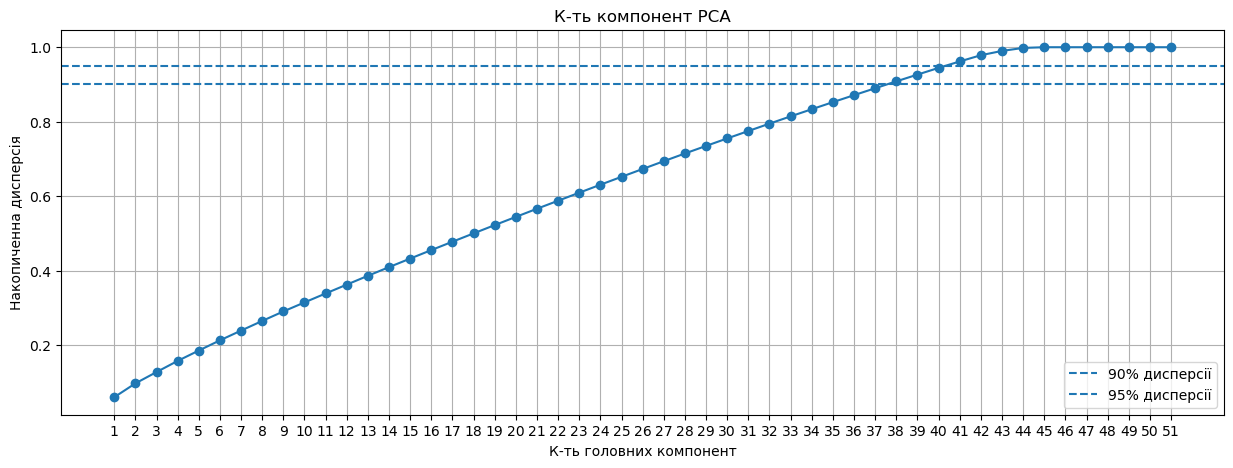

In [82]:
plt.figure(figsize=(15, 5))
plt.plot( range(1, len(comul_var) + 1), comul_var, marker='o')
plt.axhline(y=0.90, linestyle='--', label='90% дисперсії')
plt.axhline(y=0.95, linestyle='--', label='95% дисперсії')

plt.xlabel('К-ть головних компонент')
plt.ylabel('Накопиченна дисперсія')
plt.title('К-ть компонент PCA')
plt.xticks(range(1, len(comul_var) + 1))
plt.grid(True)
plt.legend()
plt.show()

In [140]:
pca = PCA(n_components=41)
X_train_pca = pca.fit_transform(scaled_X_train)
X_test_pca = pca.transform(scaled_X_test)

In [106]:
scaled_X_train

array([[-0.01608589,  2.05487426, -1.25701145, ..., -0.4347433 ,
        -0.31687956,  2.75999896],
       [ 1.81296975, -1.03032951, -0.2653951 , ..., -0.4347433 ,
        -0.31687956, -0.36231898],
       [-1.3225542 ,  0.68367258,  1.05676004, ..., -0.4347433 ,
        -0.31687956,  2.75999896],
       ...,
       [-0.53867322,  0.68367258, -0.59593388, ..., -0.4347433 ,
        -0.31687956, -0.36231898],
       [-1.7144947 ,  0.34087217, -0.2653951 , ..., -0.4347433 ,
        -0.31687956, -0.36231898],
       [ 1.55167609, -1.71593034, -0.2653951 , ...,  2.30020798,
        -0.31687956, -0.36231898]], shape=(4800, 51))

In [107]:
X_train_pca

array([[-2.17042312,  0.73994298, -0.35059695, ...,  1.56912365,
         0.21173676,  0.33627032],
       [-1.23510096, -1.96019065, -0.56813295, ..., -0.03201951,
         0.43673427,  0.29300766],
       [ 1.77372936,  1.00813115, -2.05536111, ..., -0.59725634,
         1.23499066,  0.39025735],
       ...,
       [-1.68128688, -2.73948338, -0.14272214, ..., -1.14579422,
        -1.81174518, -0.84597713],
       [ 1.82040388,  1.33283155, -0.92194514, ...,  0.09017077,
        -1.18526547,  1.55186934],
       [ 1.54163855,  1.33519273,  1.02810998, ...,  1.44645416,
        -0.77169176,  0.10589044]], shape=(4800, 41))

In [171]:
model_DT = DecisionTreeClassifier(criterion='entropy', max_depth=5, class_weight='balanced', min_samples_leaf=7, min_samples_split=14, random_state=42)

In [172]:
t0 = time.perf_counter()
model_DT.fit(X_train_pca, y_train)
print(f"Час навчання: {time.perf_counter() - t0:.4f} с")

Час навчання: 0.0954 с


In [110]:
y_pred = model_DT.predict(X_test_pca)

In [111]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.27      0.22      0.24       226
           1       0.27      0.48      0.34       219
           2       0.79      0.66      0.72       755

    accuracy                           0.54      1200
   macro avg       0.44      0.45      0.43      1200
weighted avg       0.60      0.54      0.56      1200



In [112]:
print(confusion_matrix(y_test, y_pred))

[[ 49 114  63]
 [ 45 105  69]
 [ 87 173 495]]


In [89]:
pipe = Pipeline([('pca', PCA()),
                 ('D_tree', DecisionTreeClassifier(criterion='entropy', max_depth=5, class_weight='balanced', min_samples_leaf=7, min_samples_split=14, random_state=42))])

In [97]:
param_grid = {'pca__n_components' : range(1, 50)}

In [98]:
grid = GridSearchCV(pipe, param_grid, cv=5,refit=True, scoring='f1_macro')

In [99]:
grid.fit(scaled_X_train, y_train)

,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'pca__n_components': range(1, 50)}"
,scoring,'f1_macro'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_components,10


In [100]:
grid.best_params_

{'pca__n_components': 10}

In [101]:
grid.best_estimator_

,steps,"[('pca', ...), ('D_tree', ...)]"
,transform_input,None
,memory,None
,verbose,False
,n_components,10
,copy,True
,whiten,False
,svd_solver,'auto'
,tol,0.0
,iterated_power,'auto'
,n_oversamples,10


In [173]:
pca = PCA(n_components=10)
X_train_pca = pca.fit_transform(scaled_X_train)
X_test_pca = pca.transform(scaled_X_test)

In [174]:
model_DT = DecisionTreeClassifier(criterion='entropy', max_depth=5, class_weight='balanced', min_samples_leaf=7, min_samples_split=14, random_state=42)

In [175]:
t0 = time.perf_counter()
model_DT.fit(X_train_pca, y_train)
print(f"Час навчання: {time.perf_counter() - t0:.4f} с")

Час навчання: 0.0345 с


In [176]:
y_pred = model_DT.predict(X_test_pca)

In [177]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.25      0.29      0.27       226
           1       0.25      0.42      0.31       219
           2       0.80      0.60      0.69       755

    accuracy                           0.51      1200
   macro avg       0.43      0.44      0.42      1200
weighted avg       0.60      0.51      0.54      1200



In [178]:
print(confusion_matrix(y_test, y_pred))

[[ 66 103  57]
 [ 70  92  57]
 [123 178 454]]


**Загальна таблиця метрик (Accuracy, Macro F1, Weighted F1)**

| Модель | Accuracy | Macro Precision | Macro Recall | Macro F1 | Weighted F1 | Час навчання, с |
|---|---|---|---|---|---|---|
| **Decision Tree (baseline)** | **0.57** | 0.45 | 0.45 | **0.45** | **0.58** | **0.0176** |
| **Decision Tree + PCA (41)** | 0.54 | 0.44 | **0.45** | 0.43 | 0.56 | 0.0954 |
| **Decision Tree + PCA (10)** | 0.51 | 0.43 | 0.44 | 0.42 | 0.54 | 0.0345 |

---

**Confusion Matrix**

| Модель | Confusion Matrix |
|--------|------------------|
| **Decision Tree (baseline)** | `[[57, 96, 73], [55, 85, 79], [71, 144, 540]]` |
| **Decision Tree + PCA (41)** | `[[49, 114, 63], [45, 105, 69], [87, 173, 495]]` |
| **Decision Tree + PCA (10)** | `[[66, 103, 57], [70, 92, 57], [123, 178, 454]]` |

---

In [411]:
tsne = TSNE(n_components=2, init='pca', random_state=42)
tsne_result = tsne.fit_transform(scaled_X_train)

In [412]:
tsne_result

array([[ 14.999877, -26.712   ],
       [-11.581909, -22.455273],
       [ 13.749935, -32.168026],
       ...,
       [-70.2032  ,  -9.334576],
       [ -8.323662, -15.1861  ],
       [ 58.294292,  29.226362]], shape=(4800, 2), dtype=float32)

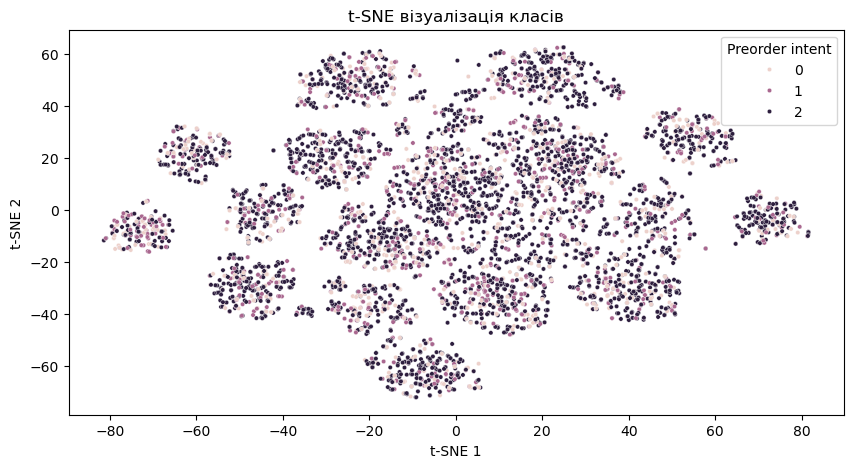

In [413]:
tsne_result_df = pd.DataFrame({'tsne_1': tsne_result[:,0], 'tsne_2': tsne_result[:,1], 'label': y_train.to_numpy()})

fig, ax = plt.subplots(figsize=(10, 5))
sns.scatterplot(x='tsne_1', y='tsne_2', hue='label', data=tsne_result_df, ax=ax,s=10)
ax.set_title('t-SNE візуалізація класів')
ax.set_xlabel('t-SNE 1')
ax.set_ylabel('t-SNE 2')
ax.legend(title='Preorder intent')
plt.show()

0 - No, 1 - Maybe, 2 - Yes

In [204]:
scaled_X_train.shape

(4800, 51)

In [205]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
kmeans.fit(scaled_X_train)
kmeans.inertia_

227654.90754111027

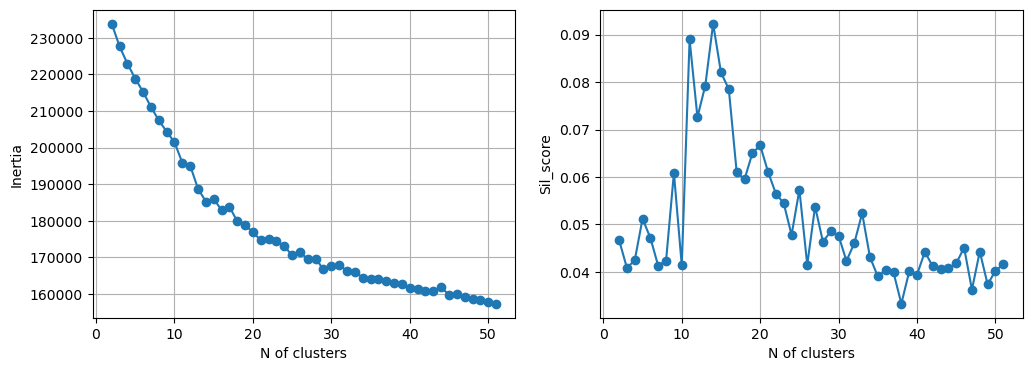

In [238]:
error = []
err_sil = []
for i in range(2, scaled_X_train.shape[1]+1):
    kmeans = KMeans(n_clusters=i, n_init=10, random_state=42)
    kmean_leb = kmeans.fit_predict(scaled_X_train)
    error.append(kmeans.inertia_)
    err_sil.append(silhouette_score(scaled_X_train, kmean_leb))


f, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(range(2, scaled_X_train.shape[1]+1), error, marker='o')
ax1.set_xlabel("N of clusters")
ax1.set_ylabel("Inertia")
ax1.grid(True)

ax2.plot(range(2, scaled_X_train.shape[1]+1), err_sil, marker='o')
ax2.set_xlabel("N of clusters")
ax2.set_ylabel("Sil_score")
ax2.grid(True)
plt.show()

14 cluster 

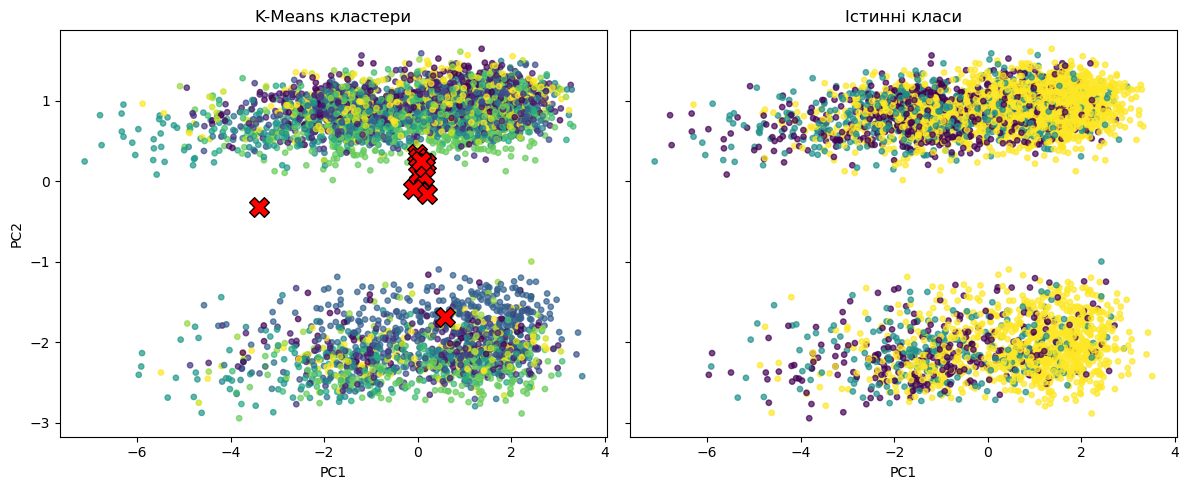

In [448]:
kmeans = KMeans(n_clusters=14, n_init=10, random_state=42)
kmeans.fit(scaled_X_train)

centers = kmeans.cluster_centers_
labels = kmeans.labels_

pca = PCA(n_components=2, random_state=42)
x2D = pca.fit_transform(scaled_X_train)
centers2D = pca.transform(kmeans.cluster_centers_)

f, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

ax1.set_title('K-Means кластери')
ax1.scatter(x2D[:, 0], x2D[:, 1], c=labels, cmap='viridis', s=15, alpha=0.7)
ax1.scatter(centers2D[:, 0], centers2D[:, 1], marker='X', color='red', s=200, edgecolor='black')
ax1.set_xlabel('PC1')
ax1.set_ylabel('PC2')

ax2.set_title('Істинні класи')
ax2.scatter(x2D[:, 0], x2D[:, 1], c=y_train, cmap='viridis', s=15, alpha=0.7)
ax2.set_xlabel('PC1')

plt.tight_layout()
plt.show()

In [420]:
comparison = pd.crosstab(
    labels,
    y_train,
    rownames=['Cluster'],
    colnames=['Real class']
)

comparison

Real class,0,1,2
Cluster,,,
0,49,33,178
1,117,107,400
2,50,41,175
3,55,54,212
4,57,46,208
5,73,62,223
6,46,52,193
7,45,55,55
8,48,49,180


In [422]:
data_nlp = pd.read_csv("emails.csv")
data_nlp

,text,spam
0,Subject: naturally irresistible your corporate...,1
1,Subject: the stock trading gunslinger fanny i...,1
2,Subject: unbelievable new homes made easy im ...,1
3,Subject: 4 color printing special request add...,1
4,"Subject: do not have money , get software cds ...",1
...,...,...
5723,Subject: re : research and development charges...,0
5724,"Subject: re : receipts from visit jim , than...",0
5725,Subject: re : enron case study update wow ! a...,0
5726,"Subject: re : interest david , please , call...",0


In [423]:
data_nlp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5728 entries, 0 to 5727
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    5728 non-null   object
 1   spam    5728 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 89.6+ KB


In [424]:
stop_words = set(stopwords.words('english'))
stop_words

{'a',
 'about',
 'above',
 'after',
 'again',
 'against',
 'ain',
 'all',
 'am',
 'an',
 'and',
 'any',
 'are',
 'aren',
 "aren't",
 'as',
 'at',
 'be',
 'because',
 'been',
 'before',
 'being',
 'below',
 'between',
 'both',
 'but',
 'by',
 'can',
 'couldn',
 "couldn't",
 'd',
 'did',
 'didn',
 "didn't",
 'do',
 'does',
 'doesn',
 "doesn't",
 'doing',
 'don',
 "don't",
 'down',
 'during',
 'each',
 'few',
 'for',
 'from',
 'further',
 'had',
 'hadn',
 "hadn't",
 'has',
 'hasn',
 "hasn't",
 'have',
 'haven',
 "haven't",
 'having',
 'he',
 "he'd",
 "he'll",
 "he's",
 'her',
 'here',
 'hers',
 'herself',
 'him',
 'himself',
 'his',
 'how',
 'i',
 "i'd",
 "i'll",
 "i'm",
 "i've",
 'if',
 'in',
 'into',
 'is',
 'isn',
 "isn't",
 'it',
 "it'd",
 "it'll",
 "it's",
 'its',
 'itself',
 'just',
 'll',
 'm',
 'ma',
 'me',
 'mightn',
 "mightn't",
 'more',
 'most',
 'mustn',
 "mustn't",
 'my',
 'myself',
 'needn',
 "needn't",
 'no',
 'nor',
 'not',
 'now',
 'o',
 'of',
 'off',
 'on',
 'once',
 'on

In [425]:
stop_words.update(['enron', 'hou', 'ect', 'cc', 'pm', 'u', 'j', 'http', 'www', 'com', 'vince', 'kaminski'])

In [426]:
data_nlp['text'][0]

"Subject: naturally irresistible your corporate identity  lt is really hard to recollect a company : the  market is full of suqgestions and the information isoverwhelminq ; but a good  catchy logo , stylish statlonery and outstanding website  will make the task much easier .  we do not promise that havinq ordered a iogo your  company will automaticaily become a world ieader : it isguite ciear that  without good products , effective business organization and practicable aim it  will be hotat nowadays market ; but we do promise that your marketing efforts  will become much more effective . here is the list of clear  benefits : creativeness : hand - made , original logos , specially done  to reflect your distinctive company image . convenience : logo and stationery  are provided in all formats ; easy - to - use content management system letsyou  change your website content and even its structure . promptness : you  will see logo drafts within three business days . affordability : your  ma

In [427]:
word_tokenize(data_nlp['text'][0])

['Subject',
 ':',
 'naturally',
 'irresistible',
 'your',
 'corporate',
 'identity',
 'lt',
 'is',
 'really',
 'hard',
 'to',
 'recollect',
 'a',
 'company',
 ':',
 'the',
 'market',
 'is',
 'full',
 'of',
 'suqgestions',
 'and',
 'the',
 'information',
 'isoverwhelminq',
 ';',
 'but',
 'a',
 'good',
 'catchy',
 'logo',
 ',',
 'stylish',
 'statlonery',
 'and',
 'outstanding',
 'website',
 'will',
 'make',
 'the',
 'task',
 'much',
 'easier',
 '.',
 'we',
 'do',
 'not',
 'promise',
 'that',
 'havinq',
 'ordered',
 'a',
 'iogo',
 'your',
 'company',
 'will',
 'automaticaily',
 'become',
 'a',
 'world',
 'ieader',
 ':',
 'it',
 'isguite',
 'ciear',
 'that',
 'without',
 'good',
 'products',
 ',',
 'effective',
 'business',
 'organization',
 'and',
 'practicable',
 'aim',
 'it',
 'will',
 'be',
 'hotat',
 'nowadays',
 'market',
 ';',
 'but',
 'we',
 'do',
 'promise',
 'that',
 'your',
 'marketing',
 'efforts',
 'will',
 'become',
 'much',
 'more',
 'effective',
 '.',
 'here',
 'is',
 'the'

In [428]:
len(data_nlp)

5728

In [429]:
for i in range(len(data_nlp)):
    text = data_nlp['text'].iloc[i]
    text = re.sub(r'<.*?>', ' ', text) # Remove HTML characters and special characters
    text = re.sub(r'&\w+;', ' ', text) # -''-
    text = text.lower() # Convert to lowercase
    text = re.sub(r"^subject:.*?:", "", text) # Remove subjects
    text = re.sub(r'\s*-\s*', '', text) # Remove - between two words
    text = re.sub(r'[%s]' % re.escape(string.punctuation), ' ', text) # Remove punctuations
    text = re.sub(r'\s{2,}', " ", text) # Remove extra space
    text = ' '.join([word for word in text.split(' ') if word not in stop_words]) # Remove stop_words
    data_nlp.loc[i, 'text'] = text
data_nlp

,text,spam
0,market full suqgestions information isoverwhe...,1
1,subject stock trading gunslinger fanny merrill...,1
2,subject unbelievable new homes made easy im wa...,1
3,626 3388090 fax 626 3388102 email ramsey gold...,1
4,subject money get software cds software compat...,1
...,...,...
5723,research development charges gpg forwarded sh...,0
5724,receipts visit jim thanks invitation visit ls...,0
5725,case study update wow day super thank much co...,0
5726,interest david please call shirley crenshaw a...,0


In [430]:
data_nlp['text'][0]

' market full suqgestions information isoverwhelminq good catchy logo stylish statlonery outstanding website make task much easier promise havinq ordered iogo company automaticaily become world ieader isguite ciear without good products effective business organization practicable aim hotat nowadays market promise marketing efforts become much effective list clear benefits creativeness handmade original logos specially done reflect distinctive company image convenience logo stationery provided formats easytouse content management system letsyou change website content even structure promptness see logo drafts within three business days affordability marketing breakthrough make gaps budget 100 satisfaction guaranteed provide unlimited amount changes extra fees surethat love result collaboration look portfolio interested '

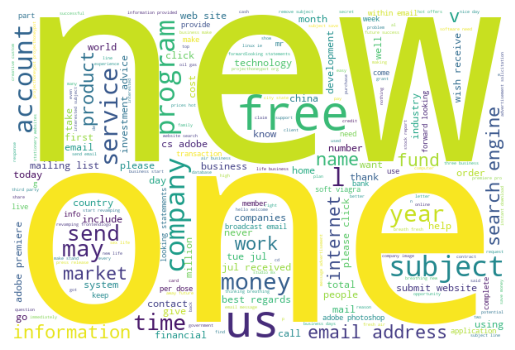

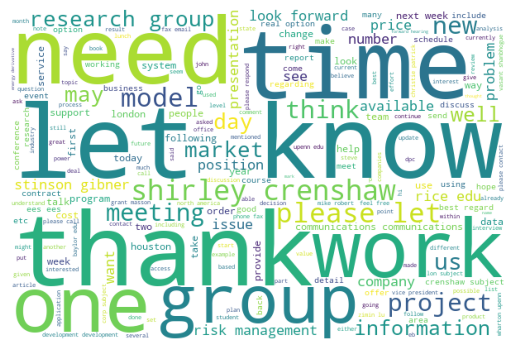

In [431]:
def visualize(label):
    text = ''
    for msg in data_nlp[data_nlp['spam'] == label]['text']:
        msg = msg.lower()
        text += msg + ' '
    wordcloud = WordCloud(width=600, height=400,  background_color="white").generate(text)
    plt.imshow(wordcloud)
    plt.axis('off')
    plt.show()

visualize(1)
visualize(0)

In [432]:
X_train, X_test, y_train, y_test = train_test_split(data_nlp['text'], data_nlp['spam'], test_size=0.2, shuffle=True, stratify=data_nlp['spam'], random_state=42)

In [433]:
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(4582,)
(4582,)
(1146,)
(1146,)


In [434]:
vectorizer = TfidfVectorizer(max_df=500, min_df=10)
X_train_transformed = vectorizer.fit_transform(X_train)
X_test_transformed = vectorizer.transform(X_test)

In [435]:
X_train_transformed

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 262500 stored elements and shape (4582, 5170)>

In [436]:
clf = MultinomialNB(alpha=0.1)
clf.fit(X_train_transformed, y_train)
y_pred = clf.predict(X_test_transformed)

In [437]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.97      0.99      0.98       872
           1       0.97      0.89      0.93       274

    accuracy                           0.97      1146
   macro avg       0.97      0.94      0.95      1146
weighted avg       0.97      0.97      0.97      1146



In [438]:
print(confusion_matrix(y_test, y_pred))

[[865   7]
 [ 30 244]]
